In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
ds = pd.read_csv("ai_companion_dependency_dataset.csv")

target = "dependency_risk_label"

X = ds.drop(columns=["user_id", target])
y = ds[target]

In [12]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Encoded Classes:", label_encoder.classes_)

Encoded Classes: ['High' 'Low' 'Moderate']


In [ ]:
# print(ds["occupation_status"].unique())


# numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
# categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

# print(numeric_features)
# print(categorical_features)

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

numeric_features = ['age', 'daily_ai_chat_hours', 'human_social_interaction_hours', 'social_media_hours_daily', 
                    'screen_time_total_hours', 'number_of_close_friends', 'loneliness_score', 'emotional_attachment_score', 
                    'real_relationship_satisfaction', 'sleep_hours', 'sleep_quality_score', 'exercise_hours_weekly', 'anxiety_score', 
                    'depression_score', 'stress_score', 'self_esteem_score']
nominal_features = ['gender', 'occupation_status', 'relationship_status', 
                    'living_situation', 'country_region', 'ai_chatbot_platform', 'primary_use_case', 'prefers_ai_over_humans', 
                    'academic_or_work_performance_change', 'therapy_attendance']
ordinal_features = ['income_level', 'education_level']

income_order = ['Low', 'Lower-Middle', 'Upper-Middle', 'High'] 
education_order = ['High School', 'Undergraduate', 'Graduate', 'Postgraduate']

numeric_pipeline = Pipeline(steps = [
                        ("imputer", SimpleImputer(strategy='mean')),
                        ("scaler", StandardScaler())
])

nominal_pipeline = Pipeline(steps = [
                        ("imputer", SimpleImputer(strategy='most_frequent')),
                        ("encoder", OneHotEncoder(handle_unknown='ignore'))
])

ordinal_pipeline = Pipeline(steps = [
                        ("imputer", SimpleImputer(strategy='most_frequent')),
                        ("encoder", OrdinalEncoder(categories = [income_order, education_order], handle_unknown='use_encoded_value', unknown_value=-1))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat_nom", nominal_pipeline, nominal_features),
    ("cat_ord", ordinal_pipeline, ordinal_features)
])

final_pipeline = Pipeline(steps = [
                        ("preprocessor", preprocessor),
                        ("classifier", RandomForestClassifier(n_estimators=150, criterion='entropy', random_state=0, n_jobs=-1))
                        # ("classifier", GradientBoostingClassifier(n_estimators=50))
                        # ("classifier", KNeighborsClassifier(n_neighbors=5, p=2, metric='minkowski'))
                        # ("classifier", GaussianNB())
])

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.25, random_state=0, stratify=y_encoded)

# final_pipeline.fit(X_train, y_train)
# y_pred = final_pipeline.predict(X_test)

Random Forest Accuracy: 80.80%

Classification Report:
              precision    recall  f1-score   support

        High       0.89      0.84      0.86        74
         Low       0.84      0.95      0.89       130
    Moderate       0.52      0.37      0.43        46

    accuracy                           0.81       250
   macro avg       0.75      0.72      0.73       250
weighted avg       0.79      0.81      0.80       250



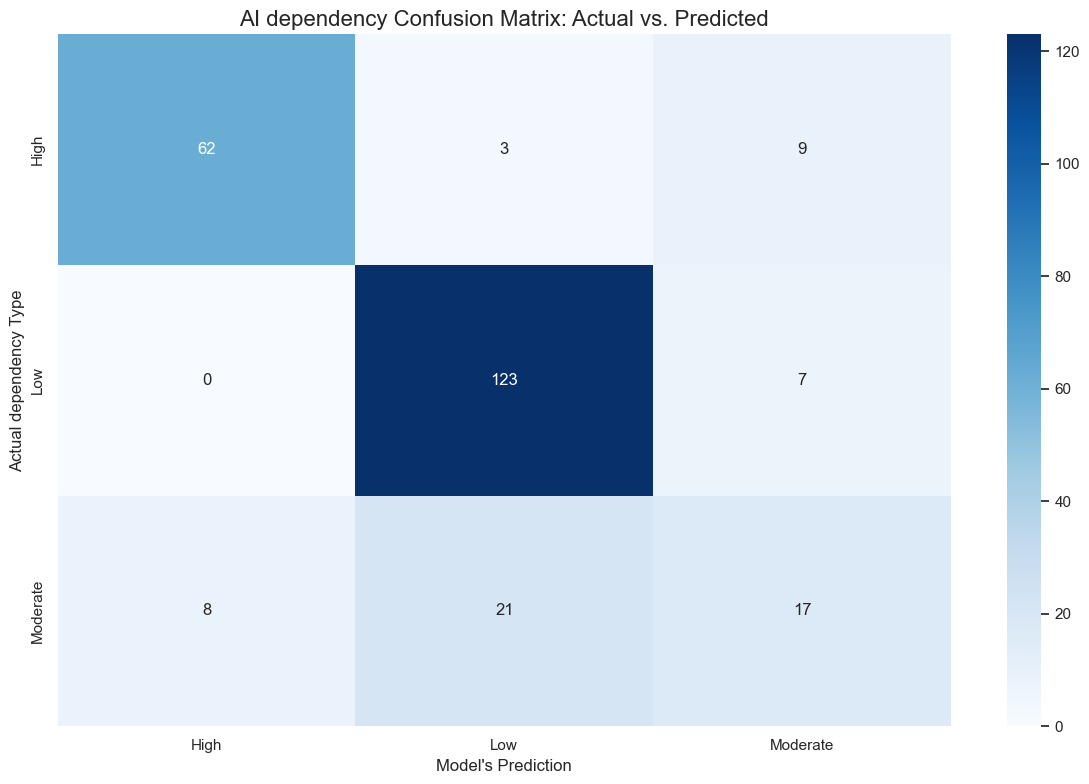

In [10]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)

plt.title("AI dependency Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual dependency Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()

RGradient Boosting Accuracy: 82.40%

Classification Report:
              precision    recall  f1-score   support

        High       0.87      0.82      0.85        74
         Low       0.88      0.94      0.91       130
    Moderate       0.56      0.50      0.53        46

    accuracy                           0.82       250
   macro avg       0.77      0.75      0.76       250
weighted avg       0.82      0.82      0.82       250



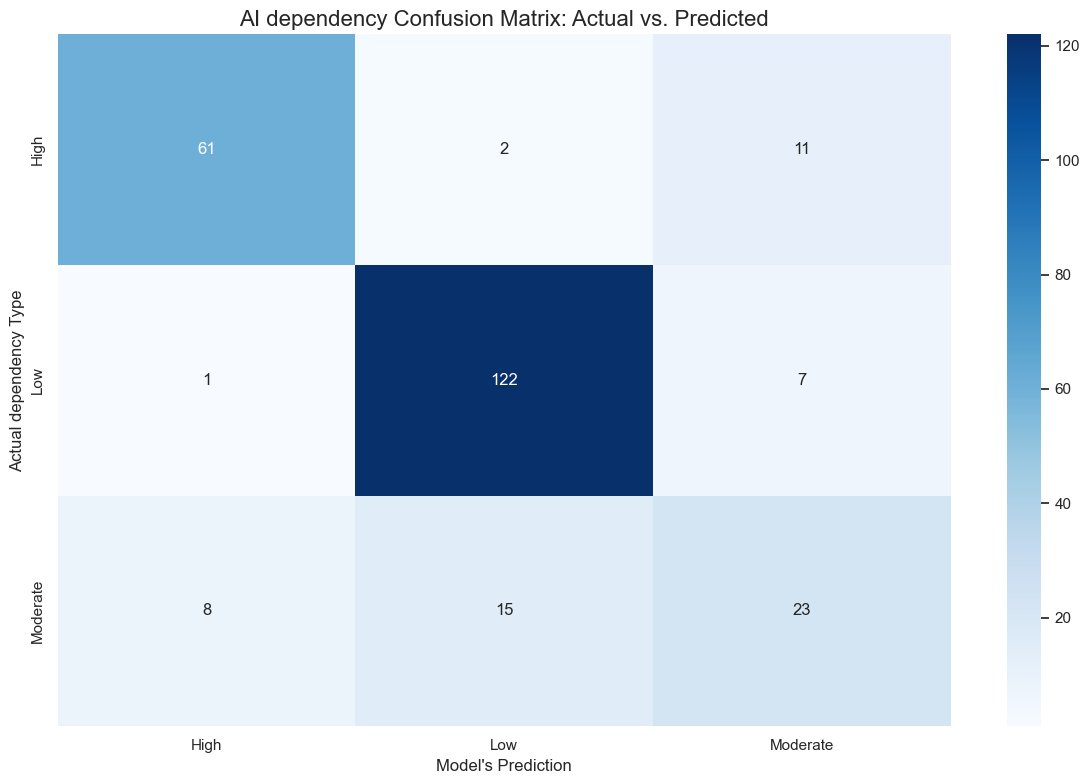

In [12]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"Gradient Boosting Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)

plt.title("AI dependency Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual dependency Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()

K-NN Accuracy: 76.40%

Classification Report:
              precision    recall  f1-score   support

        High       0.81      0.78      0.79        74
         Low       0.82      0.95      0.88       130
    Moderate       0.36      0.22      0.27        46

    accuracy                           0.76       250
   macro avg       0.66      0.65      0.65       250
weighted avg       0.73      0.76      0.74       250



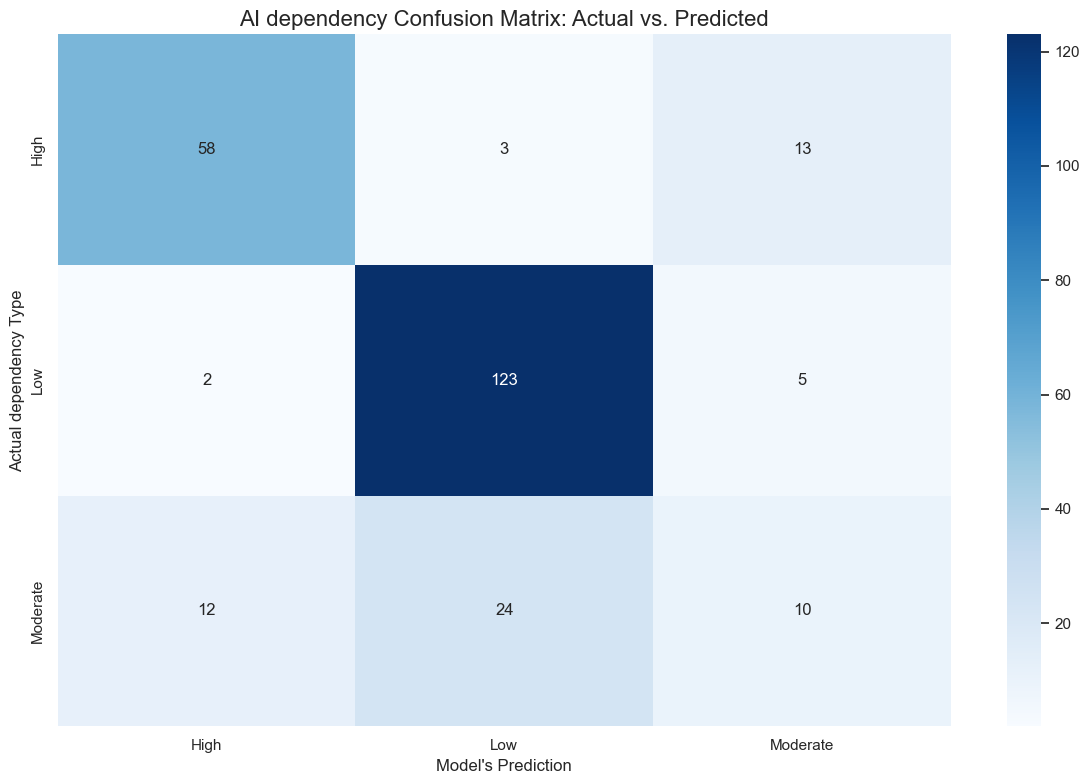

In [17]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"K-NN Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)

plt.title("AI dependency Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual dependency Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()

Naive Bayes Accuracy: 76.00%

Classification Report:
              precision    recall  f1-score   support

        High       0.88      0.66      0.75        74
         Low       0.95      0.83      0.89       130
    Moderate       0.41      0.72      0.52        46

    accuracy                           0.76       250
   macro avg       0.74      0.74      0.72       250
weighted avg       0.83      0.76      0.78       250



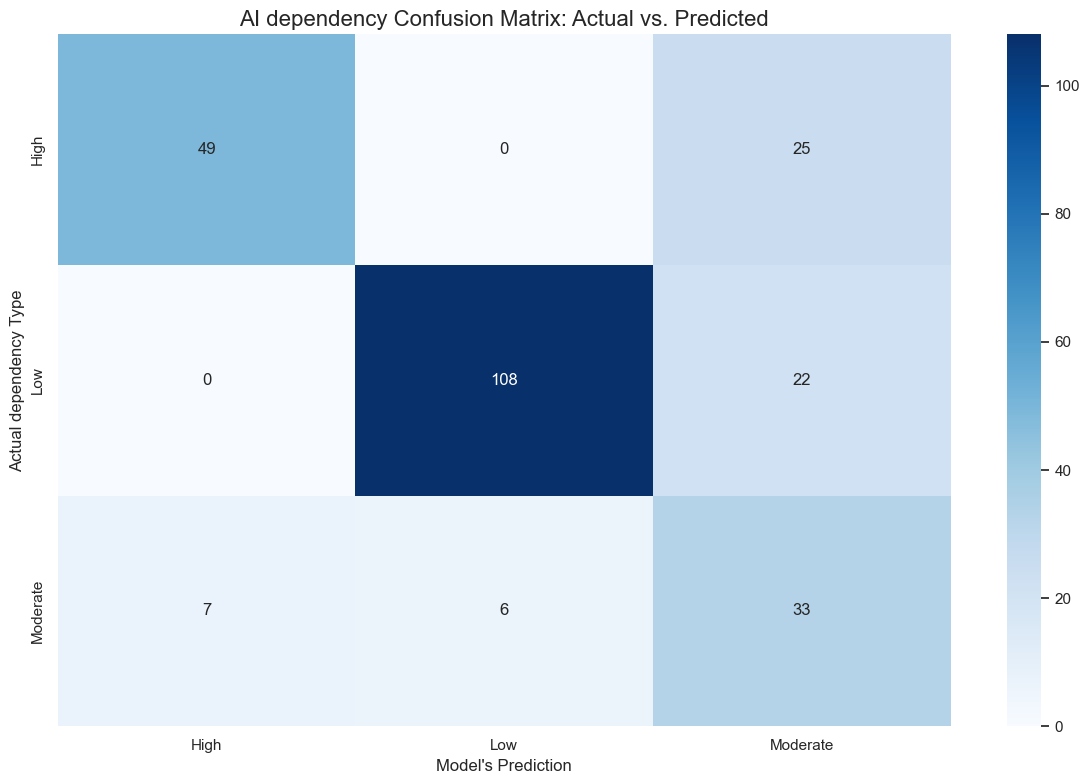

In [22]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"Naive Bayes Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)

plt.title("AI dependency Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual dependency Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()

In [15]:
from sklearn.model_selection import GridSearchCV

# 1. Define the settings you want to test
param_grid = {
    'classifier__n_estimators': [50, 70, 100, 150, 200],
    'classifier__max_depth': [None, 1, 5, 10],
    'classifier__class_weight': [None, 'balanced']
}

# 2. Put the car (final_pipeline) on the test track (GridSearchCV)
grid_search = GridSearchCV(
    estimator=final_pipeline, 
    param_grid=param_grid, 
    cv=5,               
    scoring='accuracy', 
    n_jobs=-1           
)

# 3. Start the race! (This replaces final_pipeline.fit)
grid_search.fit(X_train, y_train)

# 4. Print the winner
print("Best Settings Found:", grid_search.best_params_)

# 5. Make predictions using the winning model
y_pred = grid_search.predict(X_test)

Best Settings Found: {'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__n_estimators': 150}


Random Forest Accuracy: 80.80%

Classification Report:
              precision    recall  f1-score   support

        High       0.89      0.84      0.86        74
         Low       0.84      0.95      0.89       130
    Moderate       0.52      0.37      0.43        46

    accuracy                           0.81       250
   macro avg       0.75      0.72      0.73       250
weighted avg       0.79      0.81      0.80       250



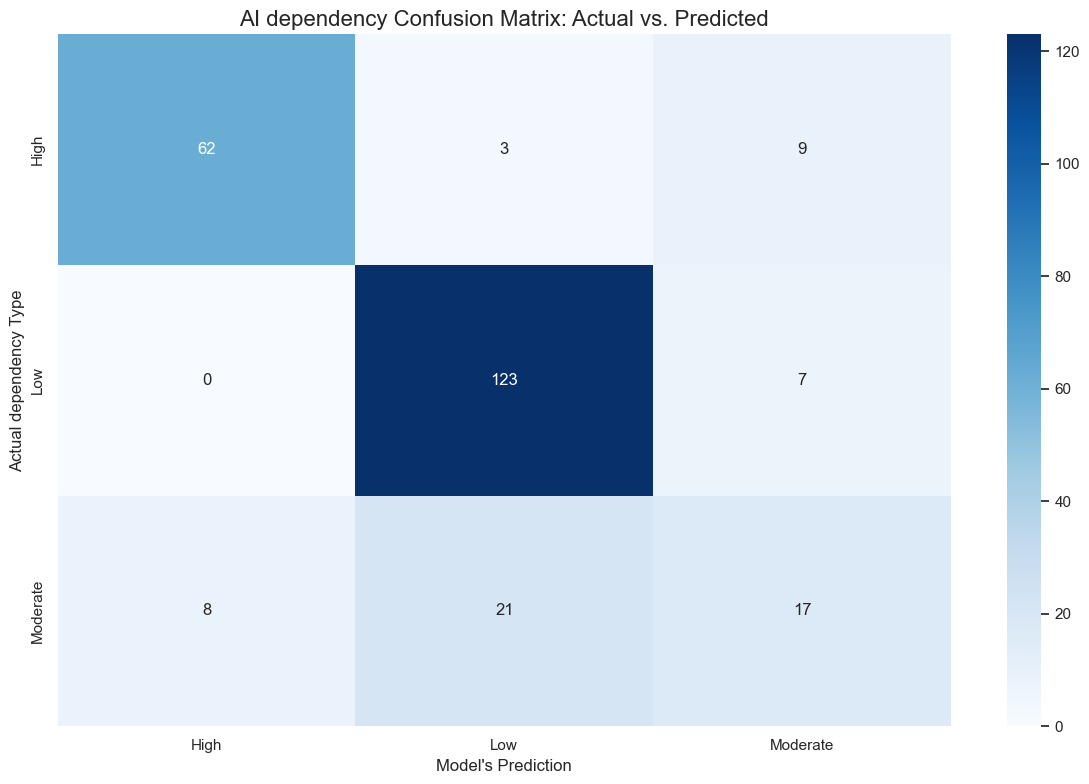

In [16]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)

plt.title("AI dependency Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual dependency Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()